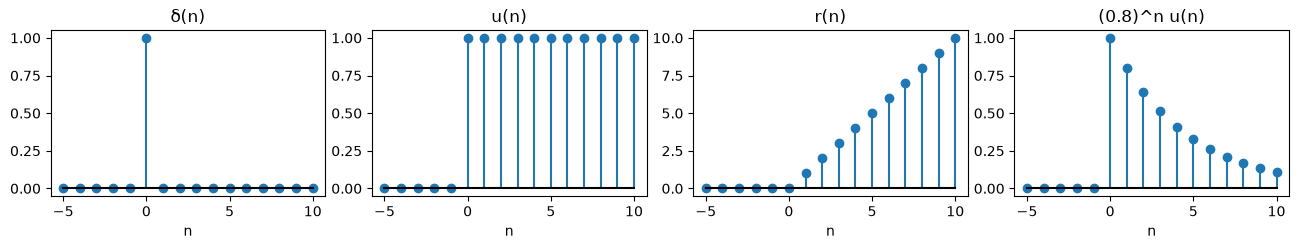

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

n = np.arange(-5, 11) 
delta = (n == 0).astype(float)       # unit impulse 
step  = (n >= 0).astype(float)       # unit step 
ramp  = n * step                     # unit ramp 
expo  = 0.8**n * step                # real exponential 

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6)) 
for ax, x, title in zip(axes, [delta, step, ramp, expo], 
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]): 
    ax.stem(n, x, basefmt="k-") 
    ax.set_title(title); ax.set_xlabel("n") 
plt.tight_layout(); plt.show() 

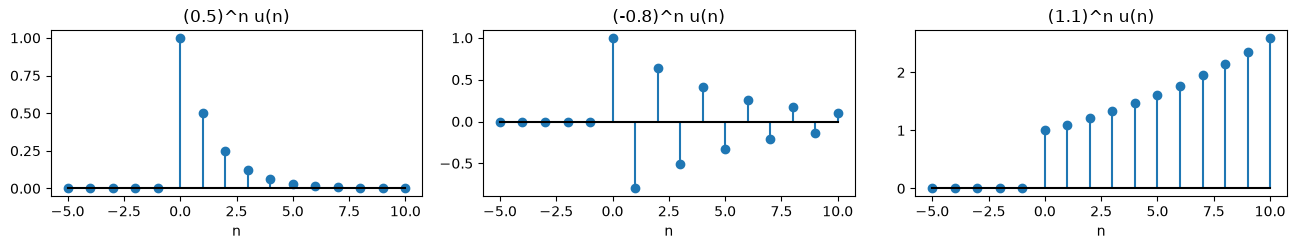

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

n = np.arange(-5, 11)
step  = (n >= 0).astype(float)       # unit step 
fig, axes = plt.subplots(1, 3, figsize=(13, 2.6)) 
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x=(a**n.astype(float))*step
    ax.stem(n, x, basefmt="k-") 
    ax.set_title(f"({a})^n u(n)"); ax.set_xlabel("n") 
plt.tight_layout(); plt.show()

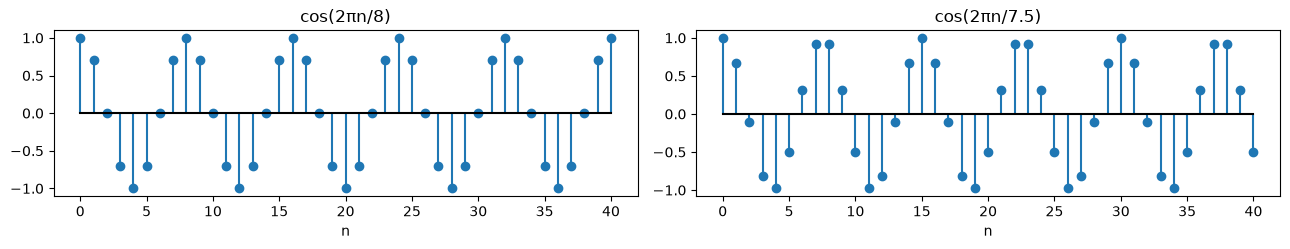

In [3]:
import numpy as np
from numpy import pi
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

n = np.arange(0, 41)
c1 = np.cos(2*np.pi*n/8)
c2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 2.6))
for ax, x, title in zip(axes, [c1, c2],
                        ["cos(2πn/8)", "cos(2πn/7.5)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

fs = 44100 Hz, duration = 3.99 s, samples = 176128


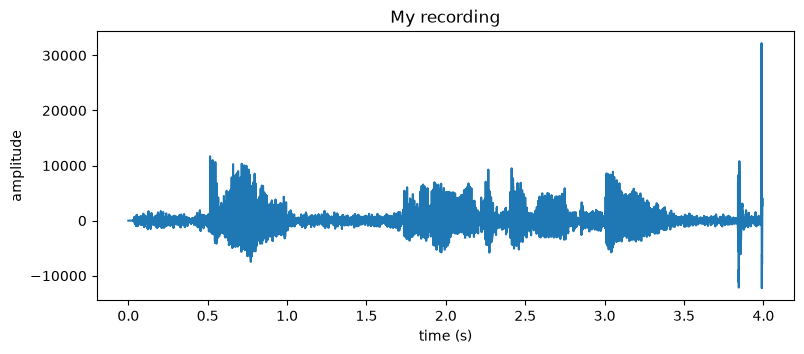

In [4]:
import numpy as np
from numpy import pi
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

import os
fname = "my_voice.wav"                      
if os.path.exists(fname):
    fs, x = wavfile.read(fname) 
    if x.ndim > 1:                          # stereo -> mono 
        x = x.mean(axis=1) 
        x = x / np.max(np.abs(x))               # normalise to [-1, 1] 
else:                                       # fallback test signal 
    fs = 16000 
    t = np.arange(0, 2, 1/fs) 
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t) 
t = np.arange(len(x)) / fs 
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}") 
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude") 
plt.title("My recording"); plt.show() 



Pre-lab question: 
list three devices you used today that contain DSP, and for each name one signal it processes. 
Answer:
Smartphone; processes voice signal from the microphone, DSP samples it, removes noise, compresses it and sends it as digital data.
Laptop; processes the audio signal played through its speakers or headphones. DSP converts the digital samples into sound and applies volume                   control and equalization.
Wi-Fi router; processes the radio signal carrying data. DSP demodulates it and corrects errors.

Analysis questions:
1. What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?
Answer:
The printed output was fs = 44100 Hz, duration = 3.99 s, samples = 176128. So the recording has a sampling rate of 44,100 Hz, meaning 44,100 samples (numbers) are taken every second. For one minute (60 s) in mono, only one channel is stored: Number of samples = f s x duration = 44100 x 60 = 2,646,000 numbers.

2. Why is a stem plot more appropriate than a continuous line for 𝑥(𝑛)?
Answer:
A stem plot draws a separate vertical line and dot at each integer n, so it shows exactly what the signal is: a sequence of individual values. A continuous line joins the points and wrongly suggests that the signal has values between the samples. It can also hide important features such as the single sample of the unit impulse δ(n), or the sign change at every sample.

3. For 𝑎 = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?  
Answer:
It would violate BIBO stability (bounded-input, bounded-output). An LTI system is BIBO stable if and only if its impulse response is absolutely summable.

Git repository link:
https://github.com/silvanus34/COU07506-labs
